## 0. Smoke Test

Full training is not repeated live: the outputs below are from the complete run. This cell runs every pipeline stage (load, audit, chronological split, scaling, windowing, persistence, MLP, CNN, evaluation) on a 2,000-row slice with one training epoch, so the pipeline can be verified in a few seconds. Its MAE values are not meaningful results. It then reloads the saved models in `checkpoints/` and confirms they reproduce the validation MAE recorded in `logs/final_comparison.csv`.

**Saved files:** `checkpoints/` holds the best MLP, initial CNN and tuned CNN (`.keras`); `logs/` holds per-epoch training histories (`mlp_history.csv`, `cnn_history.csv`, `grid_search/trial_N.csv`), the grid search table (`grid_search_results.csv`) and the final comparison table (`final_comparison.csv`).

In [1]:
# Smoke test: fast end-to-end check of the pipeline

import time
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Conv1D, MaxPooling1D, Flatten


def smoke_test(n_rows=2000, lookback=36):
    start = time.perf_counter()
    tf.keras.utils.set_random_seed(42)

    # Load data and check it
    data = pd.read_csv("solar_AL.txt.gz", compression="gzip", header=None)
    assert data.shape == (52560, 137), data.shape
    assert not data.isna().any().any()

    # Chronological split, scaler fitted on training only
    series = data[[0]].to_numpy()[:n_rows]
    train_end = int(n_rows * 0.8)

    scaler = StandardScaler().fit(series[:train_end])
    train = scaler.transform(series[:train_end])
    val = scaler.transform(series[train_end:])
    val = np.concatenate([train[-lookback:], val])

    # Sliding windows
    def windows(d):
        X = np.array([d[i - lookback:i] for i in range(lookback, len(d))])
        return X, d[lookback:, 0]

    X_tr, y_tr = windows(train)
    X_va, y_va = windows(val)
    assert X_tr.shape == (train_end - lookback, lookback, 1)
    assert X_va.shape == (n_rows - train_end, lookback, 1)

    y_true = scaler.inverse_transform(y_va.reshape(-1, 1)).flatten()

    def evaluate(pred_scaled):
        pred = scaler.inverse_transform(
            pred_scaled.reshape(-1, 1)
        ).flatten()
        assert pred.shape == y_true.shape
        assert np.isfinite(pred).all()
        return mean_absolute_error(y_true, pred)

    results = {"Persistence": evaluate(X_va[:, -1, 0])}

    # MLP (flattened windows) and CNN (3D windows), 1 epoch each
    mlp = Sequential([
        Input(shape=(lookback,)),
        Dense(32, activation="relu"),
        Dense(1)
    ])

    cnn = Sequential([
        Input(shape=(lookback, 1)),
        Conv1D(8, 5, activation="relu", padding="same"),
        MaxPooling1D(2),
        Flatten(),
        Dense(16, activation="relu"),
        Dense(1)
    ])

    for name, model, X_fit, X_eval in [
        ("MLP", mlp, X_tr.reshape(len(X_tr), -1), X_va.reshape(len(X_va), -1)),
        ("CNN", cnn, X_tr, X_va)
    ]:
        model.compile(optimizer="adam", loss="mse")
        model.fit(X_fit, y_tr, epochs=1, batch_size=32, verbose=0)
        results[name] = evaluate(model.predict(X_eval, verbose=0))

    print("X_train:", X_tr.shape, "X_val:", X_va.shape)
    for name, value in results.items():
        print(f"{name:<12} val MAE: {value:.4f}")

    print(f"\nSmoke test passed in {time.perf_counter() - start:.1f} s")



def check_saved_models(lookback=36):
    if not Path("logs/final_comparison.csv").exists():
        print("\nNo saved models yet: run the full notebook once to create them")
        return

    # Rebuild the full validation set exactly as in Sections 4-6
    data = pd.read_csv("solar_AL.txt.gz", compression="gzip", header=None)
    series = data[[0]].to_numpy()

    train_end = int(len(series) * 0.60)
    val_end = int(len(series) * 0.80)

    scaler = StandardScaler().fit(series[:train_end])
    train = scaler.transform(series[:train_end])
    val = scaler.transform(series[train_end:val_end])
    val = np.concatenate([train[-lookback:], val])

    X_va = np.array([val[i - lookback:i] for i in range(lookback, len(val))])
    y_true = scaler.inverse_transform(val[lookback:]).flatten()

    # Validation MAE recorded during the full run
    logged = pd.read_csv("logs/final_comparison.csv").set_index("Model")["Val MAE"]
    tuned_name = logged.index[-1]

    persistence_pred = scaler.inverse_transform(X_va[:, -1]).flatten()
    rows = [("Persistence", mean_absolute_error(y_true, persistence_pred))]

    for name, file, X in [
        ("MLP", "checkpoints/mlp_best.keras", X_va.reshape(len(X_va), -1)),
        ("CNN", "checkpoints/cnn_best.keras", X_va),
        (tuned_name, "checkpoints/cnn_tuned_best.keras", X_va)
    ]:
        model = tf.keras.models.load_model(file)
        pred = scaler.inverse_transform(
            model.predict(X, verbose=0).reshape(-1, 1)
        ).flatten()
        rows.append((name, mean_absolute_error(y_true, pred)))

    print("\nSaved models on the full validation set:")
    for name, mae in rows:
        print(f"{name:<45} MAE: {mae:.4f}  (logged: {logged[name]:.4f})")
        assert np.isclose(mae, logged[name], atol=1e-3), name

    print("Saved models match the logged results")


smoke_test()
check_saved_models()

X_train: (1564, 36, 1) X_val: (400, 36, 1)
Persistence  val MAE: 1.2323
MLP          val MAE: 4.5296
CNN          val MAE: 4.1113

Smoke test passed in 1.5 s

Saved models on the full validation set:
Persistence                                   MAE: 1.6107  (logged: 1.6107)
MLP                                           MAE: 2.0532  (logged: 2.0532)
CNN                                           MAE: 1.6962  (logged: 1.6962)
CNN (tuned: F=16, K=3, LR=0.0005)             MAE: 1.6485  (logged: 1.6485)
Saved models match the logged results


## 1. Dataset Description

**Dataset:** Solar Energy – 137 PV Plants (Alabama)

**Dataset source:** The dataset is provided through the link https://raw.githubusercontent.com/laiguokun/multivariate-time-series-data/master/solar-energy/solar_AL.txt.gz. (`solar_AL.txt.gz`)

**Exact target:** Solar power generation of Plant #1 (column 1), predicted one time step ahead.

**Unit:** The physical measurement unit is not specified in the distributed `solar_AL.txt.gz` file or its repository description. Values are therefore reported in original dataset units.

**Native frequency:** One observation every 10 minutes.

**Resampling rule:** No resampling is performed. The original 10-minute sampling frequency is preserved.

**Coverage:** The dataset contains 52,560 observations corresponding to the calendar year 2006, from January 1 to December 31. The datetime index is reconstructed from the documented year and sampling frequency because the downloaded file does not contain explicit timestamps.

**Forecasting task:** Predict the next 10-minute solar generation value using the previous 36 observations (6 hours).

**Features:** Historical solar generation values of Plant #1 only (initial univariate forecasting setup).

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("default")
from pathlib import Path

# Check dataset location
data_path = Path("solar_AL.txt.gz")

print("File exists:", data_path.exists())

# Load dataset
df = pd.read_csv(
    data_path,
    compression="gzip",
    header=None
)

# Name the columns
df.columns = [f"Plant_{i+1}" for i in range(df.shape[1])]

print("Dataset shape:", df.shape)

display(df.head(10))

File exists: True
Dataset shape: (52560, 137)


,Plant_1,Plant_2,Plant_3,Plant_4,Plant_5,Plant_6,Plant_7,Plant_8,Plant_9,Plant_10,...,Plant_128,Plant_129,Plant_130,Plant_131,Plant_132,Plant_133,Plant_134,Plant_135,Plant_136,Plant_137
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
# Create datetime index

df.index = pd.date_range(
    start="2006-01-01 00:00:00",
    periods=len(df),
    freq="10min"
)

df.index.name = "Timestamp"

print("Start time:", df.index.min())
print("End time:", df.index.max())
print("Frequency:", df.index.freq)

display(df.head(10))

Start time: 2006-01-01 00:00:00
End time: 2006-12-31 23:50:00
Frequency: <10 * Minutes>


,Plant_1,Plant_2,Plant_3,Plant_4,Plant_5,Plant_6,Plant_7,Plant_8,Plant_9,Plant_10,...,Plant_128,Plant_129,Plant_130,Plant_131,Plant_132,Plant_133,Plant_134,Plant_135,Plant_136,Plant_137
Timestamp,,,,,,,,,,,,,,,,,,,,,
2006-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2006-01-01 00:10:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2006-01-01 00:20:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2006-01-01 00:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2006-01-01 00:40:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2006-01-01 00:50:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2006-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2006-01-01 01:10:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2006-01-01 01:20:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Data Audit
The data quality checks produced the following results:
- **Missing Values:** No missing values (NaN) were detected.
- **Duplicate Timestamps:** No duplicate timestamps were found in the reconstructed datetime index.
- **Sampling Frequency:** All consecutive timestamps have a consistent interval of 10 minutes.
- **Data Coverage:** The number of observations matches the expected 52,560 time steps for a complete year at 10-minute intervals.
- **Duplicate Value Rows:** 26,952 rows repeat an earlier row across all 137 plants; 25,992 of these are all-zero nighttime rows, so they are expected and were kept.
- **Resampling:** No resampling was performed because the original 10-minute frequency was retained.

The dataset contains many zero-generation values, which are consistent with nighttime periods when solar generation is unavailable. These values were retained because they represent meaningful observations rather than missing data.

Since the original dataset does not contain explicit timestamps, the reconstructed index cannot independently verify whether any timestamps were missing or duplicated in the original data collection process. However, the dataset contains the expected number of observations for the documented period.

In [5]:
# 1. Expected number of observations
expected_rows = 365 * 24 * 6
print("Expected rows:", expected_rows)
print("Actual rows:", len(df))
print("Row count matches:", len(df) == expected_rows)

# 2. Missing values
print("\nMissing values:", df.isna().sum().sum())

# 3. Infinite values
print("Infinite values:", np.isinf(df.to_numpy()).sum())

# 4. Duplicate timestamps
print("Duplicate timestamps:", df.index.duplicated().sum())

# 5. Duplicate data rows (informational only)
print("Duplicate value rows:", df.duplicated().sum())

# 6. Timestamp interval check
intervals = df.index.to_series().diff().dropna()

print("\nInterval counts:")
print(intervals.value_counts())

# 7. Missing timestamps in constructed index
expected_index = pd.date_range(
    start="2006-01-01",
    periods=expected_rows,
    freq="10min"
)

print("\nMissing constructed timestamps:",
      len(expected_index.difference(df.index)))

# 8. Data value range
print("\nMinimum value:", df.min().min())
print("Maximum value:", df.max().max())

Expected rows: 52560
Actual rows: 52560
Row count matches: True

Missing values: 0
Infinite values: 0
Duplicate timestamps: 0
Duplicate value rows: 26938

Interval counts:
Timestamp
0 days 00:10:00    52559
Name: count, dtype: int64

Missing constructed timestamps: 0

Minimum value: 0.0
Maximum value: 88.9


## 3. Informative Exploratory Figures

Exploratory Data Analysis was performed on Plant #1 to understand the temporal patterns and variability in solar power generation before developing the forecasting models.

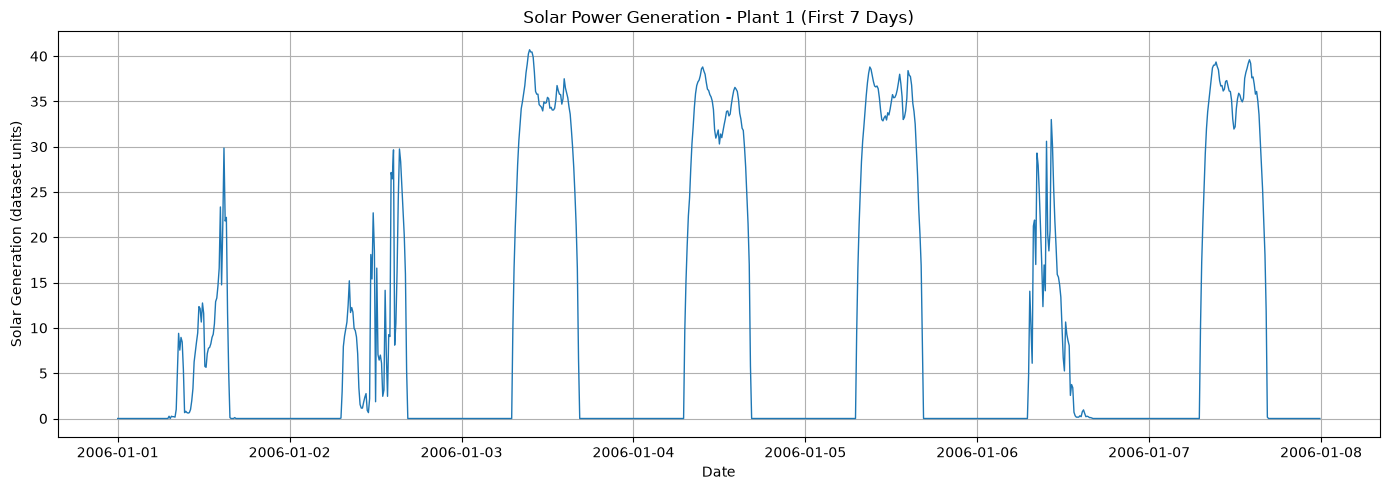

In [6]:
# Figure 1: Solar generation over 7 days (Plant 1)

plt.figure(figsize=(14, 5))

plt.plot(
    df.index[:1008],
    df["Plant_1"].iloc[:1008],
    linewidth=1
)

plt.title("Solar Power Generation - Plant 1 (First 7 Days)")
plt.xlabel("Date")
plt.ylabel("Solar Generation (dataset units)")
plt.grid(True)
plt.tight_layout()
plt.show()

**Figure 1: Solar Generation Over Seven Days**

Generation is zero overnight and follows a daily cycle, while cloudy days (Jan 1, 2 and 6) show sharp drops that make short-term forecasting harder.

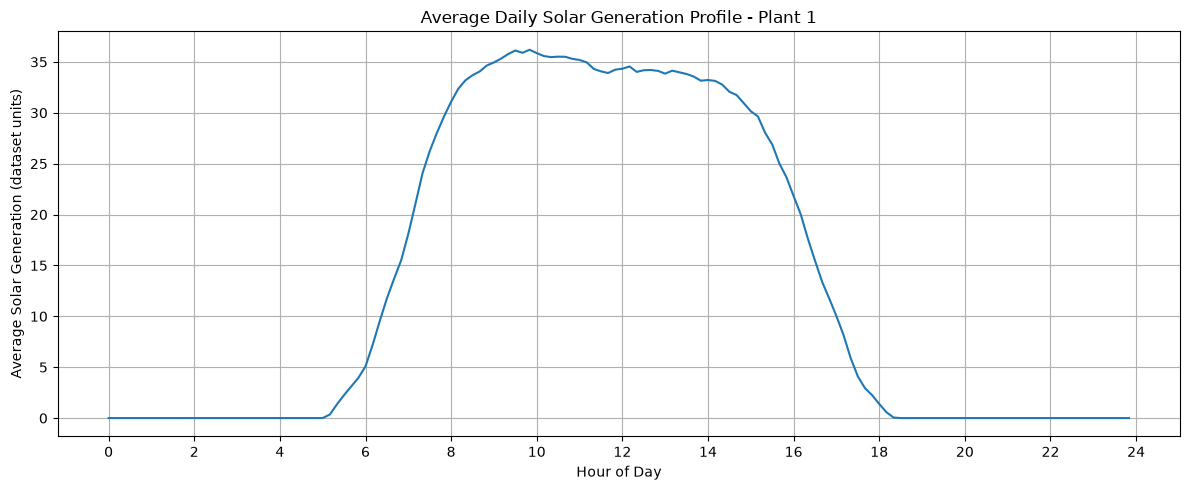

In [7]:
# Figure 2: Average solar generation by time of day (Plant 1)

plant = df["Plant_1"]

# Average generation at each 10-minute interval
daily_profile = plant.groupby(
    [plant.index.hour, plant.index.minute]
).mean()

# Convert time to decimal hours
hours = [
    hour + minute / 60
    for hour, minute in daily_profile.index
]

plt.figure(figsize=(12, 5))

plt.plot(hours, daily_profile.values)

plt.title("Average Daily Solar Generation Profile - Plant 1")
plt.xlabel("Hour of Day")
plt.ylabel("Average Solar Generation (dataset units)")
plt.xticks(range(0, 25, 2))
plt.grid(True)
plt.tight_layout()
plt.show()

**Figure 2: Average Daily Solar Generation Profile**

On average, generation starts around 05:00, stays near 34–36 units from about 09:00 to 14:00, and returns to zero by about 18:30.

**Figures 2a–2b: Autocorrelation (ACF) and Partial Autocorrelation (PACF)**

The ACF measures association with earlier observations; the PACF measures the remaining association at each lag after accounting for intervening lags. Both plots use only the first 60% of Plant #1 observations, matching the training split in Section 4. Nighttime zeros are retained.

We inspect 288 lags (48 hours): 36 steps represent the model's six-hour lookback, and 144 steps represent one day. Shaded bands show approximate 95% confidence intervals. These are descriptive diagnostics of the raw series; daily seasonality and possible nonstationarity mean the bands should not be treated as definitive significance tests or used alone to choose a model.


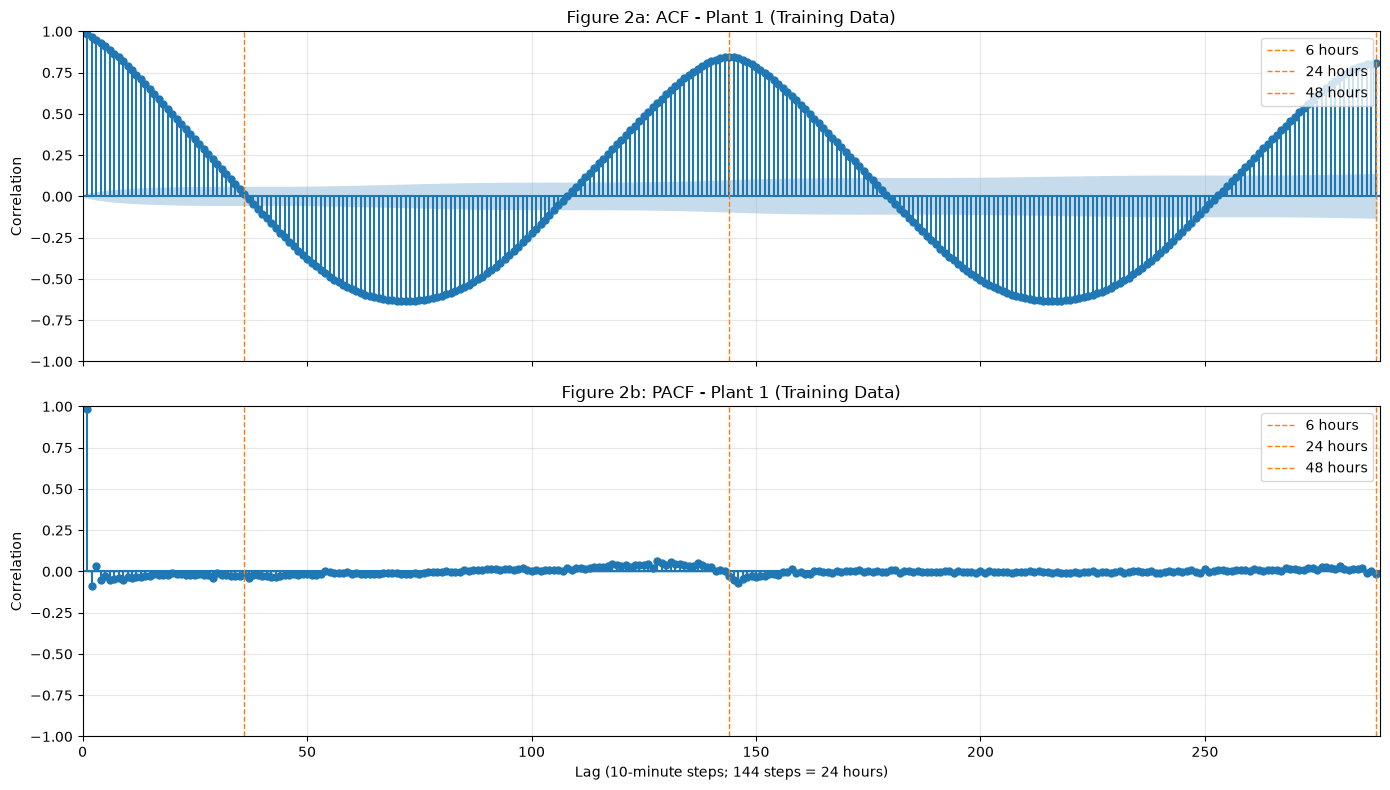

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Only use the first 60% of data to avoid data leakage
# Spotted using ChatGPT Astra
eda_train = df["Plant_1"].iloc[:int(len(df) * 0.60)]

# PACF requires the number of lags to be less than half the sample size.
max_lag = min(288, len(eda_train) // 2 - 1)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
plot_acf(eda_train, lags=max_lag, alpha=0.05, zero=False,
         fft=True, ax=axes[0])
plot_pacf(eda_train, lags=max_lag, alpha=0.05, zero=False,
          method="ld", ax=axes[1])

axes[0].set_title("Figure 2a: ACF - Plant 1")
axes[1].set_title("Figure 2b: PACF - Plant 1")
for ax in axes:
    for lag, label in [(36, "6 hours"), (144, "24 hours"), (288, "48 hours")]:
        if lag <= max_lag:
            ax.axvline(lag, color="tab:orange", linestyle="--",
                       linewidth=1, label=label)
    ax.set_ylabel("Correlation")
    ax.set_xlim(0, max_lag + 1)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")
axes[1].set_xlabel("Lag (10-minute steps; 144 steps = 24 hours)")
plt.tight_layout()
plt.show()


**Reading Figures 2a–2b**

The ACF has a wave-like shape because solar generation follows a strong daily cycle. Correlation is close to 1 at short lags, indicating that consecutive 10-minute observations are very similar. It becomes negative around lag 72 (12 hours), when daytime generation aligns with nighttime zeros, and rises to approximately 0.85 at lag 144 (24 hours), when the same times of day align again. The pattern repeats with a trough around lag 216 (36 hours) and another positive peak near lag 288 (48 hours). Negative correlation does not mean negative generation: it means values above the overall mean tend to align with values below the mean in the shifted series. Weather variability and changes in daylight prevent the daily peaks from reaching 1.

The PACF shows a dominant positive spike at lag 1, followed by much smaller values after accounting for the intervening lags. This indicates strong immediate linear dependence. The absence of a large PACF peak at 24 hours does not negate the daily cycle visible in the ACF; much of the association is explained by intermediate observations. 

For forecasting, the strong short-lag correlation helps explain why persistence is a useful baseline. The current 36-step (six-hour) input window captures recent history but does not directly include the previous day's corresponding observation at lag 144. A longer window or explicit daily-lag feature is therefore worth evaluating, with any benefit confirmed on the validation set. The approximate confidence bands are descriptive guides because the raw series has strong seasonality and may not be stationary.


## 4. Chronological Data Split

In [7]:
# Forecasting configuration
TARGET = "Plant_1"
LOOKBACK = 36
HORIZON = 1

# Select target
series = df[[TARGET]].copy()

# Calculate split boundaries
n = len(series)

train_end = int(n * 0.60)
val_end = int(n * 0.80)

# Chronological split
train_df = series.iloc[:train_end].copy()
val_df = series.iloc[train_end:val_end].copy()
test_df = series.iloc[val_end:].copy()

# Display split summary
split_summary = pd.DataFrame({
    "Split": ["Training", "Validation", "Testing"],
    "Samples": [len(train_df), len(val_df), len(test_df)],
    "Start": [
        train_df.index.min(),
        val_df.index.min(),
        test_df.index.min()
    ],
    "End": [
        train_df.index.max(),
        val_df.index.max(),
        test_df.index.max()
    ]
})

display(split_summary)

,Split,Samples,Start,End
0,Training,31536,2006-01-01,2006-08-07 23:50:00
1,Validation,10512,2006-08-08,2006-10-19 23:50:00
2,Testing,10512,2006-10-20,2006-12-31 23:50:00


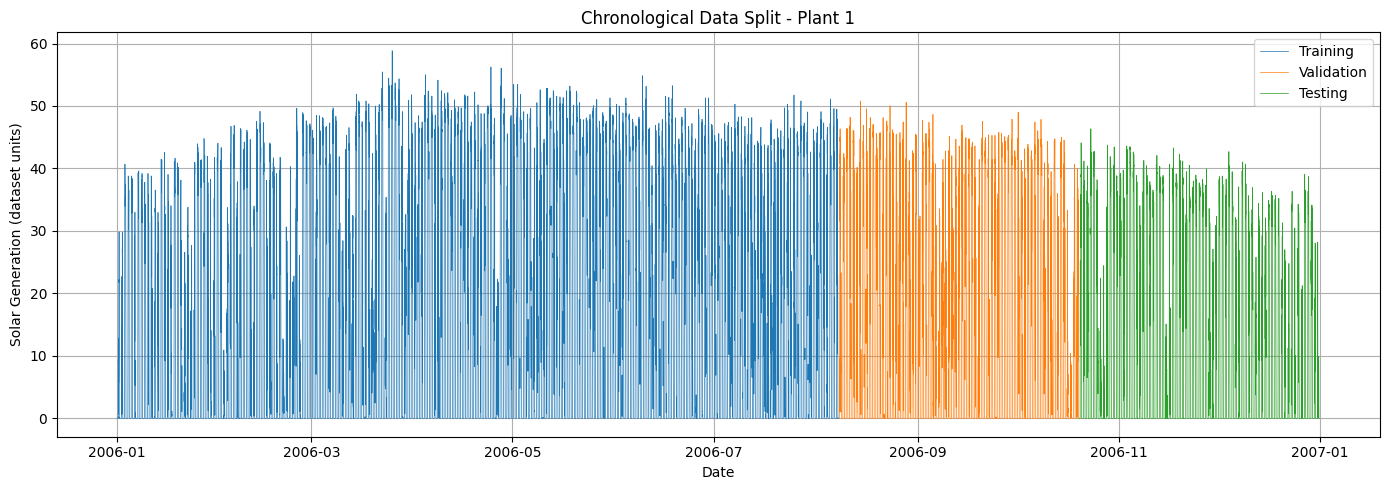

In [8]:
# Figure 3. Chronological Split Visualization

plt.style.use("default")

plt.figure(figsize=(14, 5))

plt.plot(
    train_df.index,
    train_df[TARGET],
    label="Training",
    linewidth=0.5
)

plt.plot(
    val_df.index,
    val_df[TARGET],
    label="Validation",
    linewidth=0.5
)

plt.plot(
    test_df.index,
    test_df[TARGET],
    label="Testing",
    linewidth=0.5
)

plt.title("Chronological Data Split - Plant 1")
plt.xlabel("Date")
plt.ylabel("Solar Generation (dataset units)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Figure 3. Chronological Data Split**

A 60/20/20 split gives training (Jan 1–Aug 7), validation (Aug 8–Oct 19) and testing (Oct 20–Dec 31) periods with no overlap in time.

## 5. Scaler and Imputer

In [9]:
from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Fit ONLY on training data
train_scaled = scaler.fit_transform(train_df)

# Transform validation and test data
val_scaled = scaler.transform(val_df)
test_scaled = scaler.transform(test_df)

print("Training shape:", train_scaled.shape)
print("Validation shape:", val_scaled.shape)
print("Testing shape:", test_scaled.shape)

print("\nTraining mean:", train_scaled.mean())
print("Training std:", train_scaled.std())

Training shape: (31536, 1)
Validation shape: (10512, 1)
Testing shape: (10512, 1)

Training mean: -1.1535955121422225e-16
Training std: 1.0000000000000002


StandardScaler was applied to normalize the target values. The scaler was fitted exclusively on the training set and subsequently used to transform the validation and testing sets, preventing data leakage.

No imputation was required because the dataset contained no missing values.

## 6. Sliding Window

A lookback window of **36 time steps (6 hours)** was selected to predict the next observation (10 minutes ahead). Validation and test windows are prefixed with the last 36 steps of the previous split, so every target in those sets has a full input window.

In [10]:
LOOKBACK = 36
HORIZON = 1

def create_windows(data, lookback=36, horizon=1):
    X, y = [], []

    for i in range(lookback, len(data) - horizon + 1):
        X.append(data[i-lookback:i])
        y.append(data[i+horizon-1, 0])

    return np.array(X), np.array(y)

In [11]:
# Training windows
X_train, y_train = create_windows(
    train_scaled, LOOKBACK, HORIZON
)

# Validation windows with training history
val_with_context = np.concatenate([
    train_scaled[-LOOKBACK:],
    val_scaled
])

X_val, y_val = create_windows(
    val_with_context, LOOKBACK, HORIZON
)

# Testing windows with validation history
test_with_context = np.concatenate([
    val_scaled[-LOOKBACK:],
    test_scaled
])

X_test, y_test = create_windows(
    test_with_context, LOOKBACK, HORIZON
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (31500, 36, 1)
y_train: (31500,)
X_val: (10512, 36, 1)
y_val: (10512,)
X_test: (10512, 36, 1)
y_test: (10512,)


## 7. Simple non-neural network baseline

**Persistence baseline** is used below.

In [12]:
# Predict the next value using the last observation
y_val_pred_naive_scaled = X_val[:, -1, 0]

# Convert predictions back to original units
y_val_pred_naive = scaler.inverse_transform(
    y_val_pred_naive_scaled.reshape(-1, 1)
).flatten()

# Convert actual targets back to original units
y_val_actual = scaler.inverse_transform(
    y_val.reshape(-1, 1)
).flatten()

print("Actual values:", y_val_actual[:10])
print("Predicted values:", y_val_pred_naive[:10])

Actual values: [-1.77635684e-15 -1.77635684e-15 -1.77635684e-15 -1.77635684e-15
 -1.77635684e-15 -1.77635684e-15 -1.77635684e-15 -1.77635684e-15
 -1.77635684e-15 -1.77635684e-15]
Predicted values: [-1.77635684e-15 -1.77635684e-15 -1.77635684e-15 -1.77635684e-15
 -1.77635684e-15 -1.77635684e-15 -1.77635684e-15 -1.77635684e-15
 -1.77635684e-15 -1.77635684e-15]


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Evaluate persistence baseline
naive_mae = mean_absolute_error(
    y_val_actual, y_val_pred_naive
)

naive_rmse = np.sqrt(
    mean_squared_error(
        y_val_actual, y_val_pred_naive
    )
)

print("Persistence Baseline Results")
print(f"Validation MAE: {naive_mae:.4f}")
print(f"Validation RMSE: {naive_rmse:.4f}")

Persistence Baseline Results
Validation MAE: 1.6107
Validation RMSE: 3.6799


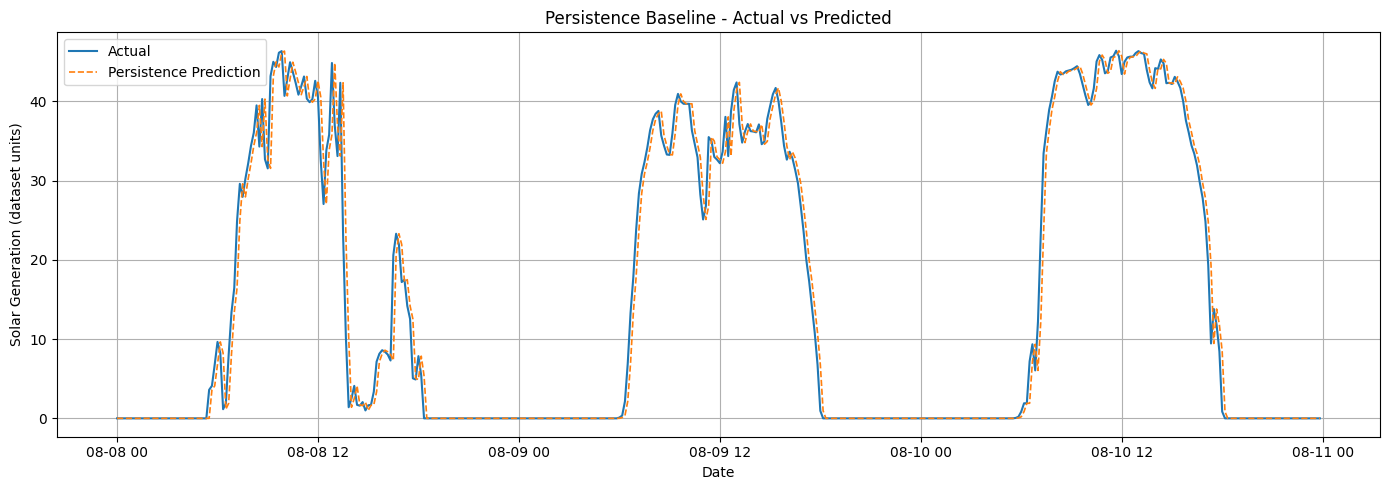

In [14]:
# Figure 4: Persistence Baseline Predictions

n_plot = 432

plt.style.use("default")
plt.figure(figsize=(14, 5))

plt.plot(
    val_df.index[:n_plot],
    y_val_actual[:n_plot],
    label="Actual",
    linewidth=1.5
)

plt.plot(
    val_df.index[:n_plot],
    y_val_pred_naive[:n_plot],
    label="Persistence Prediction",
    linewidth=1.2,
    linestyle="--"
)

plt.title("Persistence Baseline - Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Solar Generation (dataset units)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Figure 4. Persistence Baseline vs Actual Values**

The persistence forecast is the actual series shifted one step later, so it tracks smooth periods well but lags every sudden change.

## 8. Multilayer Perceptron (MLP)

In [15]:
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping, ModelCheckpoint, CSVLogger
)
import time

SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Make re-runs reproduce the same results
tf.config.experimental.enable_op_determinism()

# Saved models and training logs
CHECKPOINT_DIR = Path("checkpoints")
LOG_DIR = Path("logs")

CHECKPOINT_DIR.mkdir(exist_ok=True)
(LOG_DIR / "grid_search").mkdir(parents=True, exist_ok=True)

X_train_mlp = X_train.reshape(len(X_train), LOOKBACK)
X_val_mlp = X_val.reshape(len(X_val), LOOKBACK)

print("MLP Training Input:", X_train_mlp.shape)
print("MLP Validation Input:", X_val_mlp.shape)

MLP Training Input: (31500, 36)
MLP Validation Input: (10512, 36)


In [16]:
# Set up MLP

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

mlp = Sequential([
    Input(shape=(LOOKBACK,)),
    Dense(32, activation="relu"),
    Dense(1)
])

mlp.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse"
)

mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,217 (4.75 KB)

 Trainable params: 1,217 (4.75 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# Train the model

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

start_time = time.perf_counter()

mlp_history = mlp.fit(
    X_train_mlp,
    y_train,
    validation_data=(X_val_mlp, y_val),
    epochs=60,
    batch_size=32,
    shuffle=False,
    callbacks=[
        early_stop,
        ModelCheckpoint(
            CHECKPOINT_DIR / "mlp_best.keras",
            monitor="val_loss",
            save_best_only=True
        ),
        CSVLogger(LOG_DIR / "mlp_history.csv")
    ],
    verbose=1
)

mlp_training_time = time.perf_counter() - start_time

print("Training time:", mlp_training_time)
print("Parameters:", mlp.count_params())

Epoch 1/60



  1/985 ━━━━━━━━━━━━━━━━━━━━ 4:56 302ms/step - loss: 1.3762


 88/985 ━━━━━━━━━━━━━━━━━━━━ 0s 578us/step - loss: 0.2649  


172/985 ━━━━━━━━━━━━━━━━━━━━ 0s 588us/step - loss: 0.1806


252/985 ━━━━━━━━━━━━━━━━━━━━ 0s 601us/step - loss: 0.1490

...


796/985 ━━━━━━━━━━━━━━━━━━━━ 0s 633us/step - loss: 0.0283


877/985 ━━━━━━━━━━━━━━━━━━━━ 0s 632us/step - loss: 0.0287


963/985 ━━━━━━━━━━━━━━━━━━━━ 0s 628us/step - loss: 0.0297


985/985 ━━━━━━━━━━━━━━━━━━━━ 1s 857us/step - loss: 0.0300 - val_loss: 0.0386


Training time: 9.599333000020124
Parameters: 1217


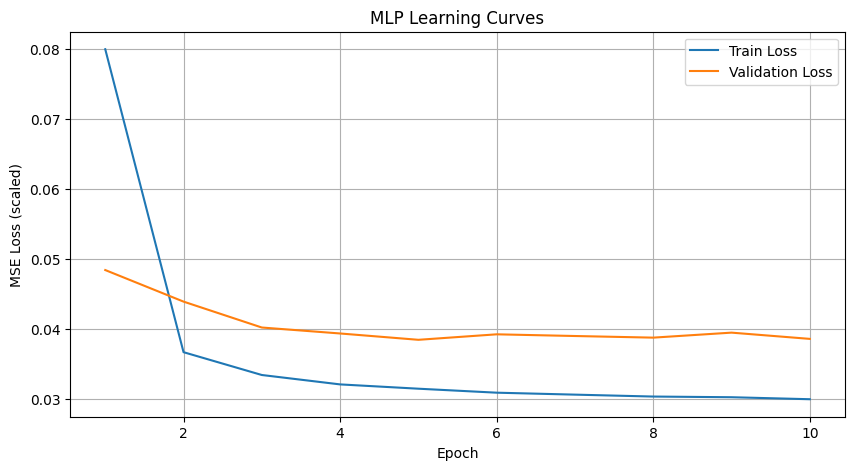

In [18]:
# Plot MLP learning curve

plt.style.use("default")

plt.figure(figsize=(10, 5))

epochs = range(1, len(mlp_history.history["loss"]) + 1)
plt.plot(epochs, mlp_history.history["loss"], label="Train Loss")
plt.plot(epochs, mlp_history.history["val_loss"], label="Validation Loss")

plt.title("MLP Learning Curves")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss (scaled)")
plt.legend()
plt.grid(True)
plt.show()

**Figure 5. MLP Learning Curves**

Validation loss levels off after about epoch 5, and early stopping ended training at epoch 10 with the epoch 5 weights restored.

In [19]:
# Evaluation

mlp_pred_scaled = mlp.predict(
    X_val_mlp,
    verbose=0
)

mlp_pred = scaler.inverse_transform(
    mlp_pred_scaled.reshape(-1, 1)
).flatten()

mlp_mae = mean_absolute_error(
    y_val_actual, mlp_pred
)

mlp_rmse = np.sqrt(
    mean_squared_error(y_val_actual, mlp_pred)
)

mlp_improvement = (
    (naive_mae - mlp_mae) / naive_mae * 100
)

print(f"MLP Validation MAE: {mlp_mae:.4f}")
print(f"MLP Validation RMSE: {mlp_rmse:.4f}")
print(f"Improvement vs Baseline: {mlp_improvement:.2f}%")

MLP Validation MAE: 2.0532
MLP Validation RMSE: 3.6332
Improvement vs Baseline: -27.47%


## 9. Convolutional Neural Network (CNN)

In [20]:
from tensorflow.keras.layers import (
    Conv1D, MaxPooling1D, Flatten
)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

cnn = Sequential([
    Input(shape=(LOOKBACK, 1)),
    Conv1D(
        filters=8,
        kernel_size=5,
        activation="relu",
        padding="same"
    ),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(16, activation="relu"),
    Dense(1)
])

cnn.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse"
)

cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 36, 8)          │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 18, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 144)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,385 (9.32 KB)

 Trainable params: 2,385 (9.32 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# Same train strategy with MLP

cnn_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

start_time = time.perf_counter()

cnn_history = cnn.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=60,
    batch_size=32,
    shuffle=False,
    callbacks=[
        cnn_early_stop,
        ModelCheckpoint(
            CHECKPOINT_DIR / "cnn_best.keras",
            monitor="val_loss",
            save_best_only=True
        ),
        CSVLogger(LOG_DIR / "cnn_history.csv")
    ],
    verbose=1
)

cnn_training_time = time.perf_counter() - start_time

Epoch 1/60



  1/985 ━━━━━━━━━━━━━━━━━━━━ 7:34 462ms/step - loss: 0.0299


 51/985 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5013    


 97/985 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3728


148/985 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2930

...


824/985 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0253


872/985 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0257


919/985 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0265


965/985 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0271


985/985 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0271 - val_loss: 0.0353


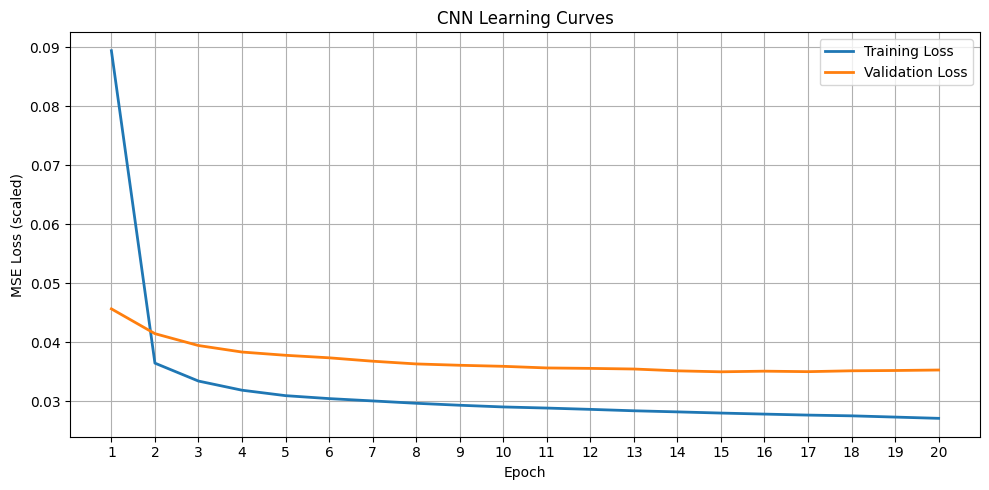

In [22]:
# Plot CNN Learning Curves

plt.style.use("default")

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cnn_history.history["loss"]) + 1),
    cnn_history.history["loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    range(1, len(cnn_history.history["val_loss"]) + 1),
    cnn_history.history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.title("CNN Learning Curves")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss (scaled)")

plt.xticks(
    range(1, len(cnn_history.history["loss"]) + 1),
    labels=range(1, len(cnn_history.history["loss"]) + 1)
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Figure 6. CNN Learning Curves**

Validation loss decreases slowly until about epoch 15, and early stopping ended training at epoch 20 with the epoch 15 weights restored.

In [23]:
# CNN validation evaluation

cnn_pred_scaled = cnn.predict(X_val, verbose=0)

cnn_pred = scaler.inverse_transform(
    cnn_pred_scaled.reshape(-1, 1)
).flatten()

cnn_mae = mean_absolute_error(
    y_val_actual, cnn_pred
)

cnn_rmse = np.sqrt(
    mean_squared_error(y_val_actual, cnn_pred)
)

cnn_improvement = (
    (naive_mae - cnn_mae) / naive_mae * 100
)

print(f"CNN Validation MAE: {cnn_mae:.4f}")
print(f"CNN Validation RMSE: {cnn_rmse:.4f}")
print(f"Improvement vs Baseline: {cnn_improvement:.2f}%")

CNN Validation MAE: 1.6962
CNN Validation RMSE: 3.4651
Improvement vs Baseline: -5.31%


In [24]:
# Protocol check

print("MLP actual epochs:",
      len(mlp_history.history["loss"]))

print("CNN actual epochs:",
      len(cnn_history.history["loss"]))

print("MLP best epoch:",
      np.argmin(mlp_history.history["val_loss"]) + 1)

print("CNN best epoch:",
      np.argmin(cnn_history.history["val_loss"]) + 1)

print("MLP validation samples:", len(y_val))
print("CNN validation samples:", len(y_val))
print("Baseline validation samples:", len(y_val_actual))

MLP actual epochs: 10
CNN actual epochs: 20
MLP best epoch: 5
CNN best epoch: 15
MLP validation samples: 10512
CNN validation samples: 10512
Baseline validation samples: 10512


## 10. Models Comparison

In [25]:
# 10. Initial Model Comparison

def improvement(mae):
    return (naive_mae - mae) / naive_mae * 100

comparison_df = pd.DataFrame([
    {
        "Model": "Persistence",
        "Val MAE": naive_mae,
        "Val RMSE": naive_rmse,
        "Parameters": 0,
        "Training Time (s)": 0.0,
        "MAE Improvement (%)": 0.0
    },
    {
        "Model": "MLP",
        "Val MAE": mlp_mae,
        "Val RMSE": mlp_rmse,
        "Parameters": mlp.count_params(),
        "Training Time (s)": mlp_training_time,
        "MAE Improvement (%)": improvement(mlp_mae)
    },
    {
        "Model": "CNN",
        "Val MAE": cnn_mae,
        "Val RMSE": cnn_rmse,
        "Parameters": cnn.count_params(),
        "Training Time (s)": cnn_training_time,
        "MAE Improvement (%)": improvement(cnn_mae)
    }
])

comparison_df["RMSE Improvement (%)"] = (
    (naive_rmse - comparison_df["Val RMSE"]) / naive_rmse * 100
)

display(comparison_df.round(4))

,Model,Val MAE,Val RMSE,Parameters,Training Time (s),MAE Improvement (%),RMSE Improvement (%)
0,Persistence,1.6107,3.6799,0,0.0000,0.0000,0.0000
1,MLP,2.0532,3.6332,1217,9.5993,-27.4665,1.2673
2,CNN,1.6962,3.4651,2385,25.0180,-5.3062,5.8373


Compared with the persistence baseline, the MLP and CNN achieved MAE improvements of −27.47% and −5.31%, so neither neural network beat persistence on average absolute error. However, both had lower RMSE than persistence (3.6332 and 3.4651 against 3.6799, which is 1.27% and 5.84% lower), meaning they make fewer large errors even though their typical error is larger.

Since the **CNN** achieved better validation MAE and RMSE than the MLP, it was selected for hyperparameter optimization using grid search.

## 11. Grid Search for CNN

All 8 configurations use the same protocol as the initial models (Adam, MSE loss, batch size 32, up to 60 epochs, early stopping with patience 5), and the best configuration is selected by validation MAE.

Tune:
```text
filters     = [8, 16]
kernel_size = [3, 5]
learning_rate = [0.0005, 0.001]
```

In [26]:
import itertools

SEED = 42

def build_cnn(filters, kernel_size, learning_rate):
    model = Sequential([
        Input(shape=(LOOKBACK, 1)),

        Conv1D(
            filters=filters,
            kernel_size=kernel_size,
            activation="relu",
            padding="same"
        ),

        MaxPooling1D(pool_size=2),
        Flatten(),

        Dense(16, activation="relu"),
        Dense(1)
    ])

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="mse"
    )

    return model

In [27]:
# Hyperparameter search space

param_grid = {
    "filters": [8, 16],
    "kernel_size": [3, 5],
    "learning_rate": [0.001, 0.0005]
}

combinations = list(itertools.product(
    param_grid["filters"],
    param_grid["kernel_size"],
    param_grid["learning_rate"]
))

grid_results = []

best_mae = float("inf")
best_config = None
best_weights = None
best_history = None

MAX_EPOCHS = 60
PATIENCE = 5
BATCH_SIZE = 32

for trial, (filters, kernel_size, lr) in enumerate(
    combinations, start=1
):

    print(f"\nTrial {trial}/{len(combinations)}")
    print(f"Filters={filters}, Kernel={kernel_size}, LR={lr}")

    # Reset model state and random seed
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_cnn(
        filters=filters,
        kernel_size=kernel_size,
        learning_rate=lr
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True
    )

    start_time = time.perf_counter()

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=False,
        callbacks=[
            early_stop,
            CSVLogger(LOG_DIR / "grid_search" / f"trial_{trial}.csv")
        ],
        verbose=0
    )

    elapsed = time.perf_counter() - start_time

    # Predict on validation set
    pred_scaled = model.predict(X_val, verbose=0)

    # Return predictions to original units
    pred_original = scaler.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).flatten()

    # Evaluate
    val_mae = mean_absolute_error(
        y_val_actual, pred_original
    )

    val_rmse = np.sqrt(
        mean_squared_error(y_val_actual, pred_original)
    )

    actual_epochs = len(history.history["loss"])

    best_epoch = (
        np.argmin(history.history["val_loss"]) + 1
    )

    # Store trial results
    grid_results.append({
        "Trial": trial,
        "Filters": filters,
        "Kernel Size": kernel_size,
        "Learning Rate": lr,
        "Val MAE": val_mae,
        "Val RMSE": val_rmse,
        "Parameters": model.count_params(),
        "Epochs": actual_epochs,
        "Best Epoch": best_epoch,
        "Training Time (s)": elapsed
    })

    print(f"Validation MAE: {val_mae:.4f}")
    print(f"Validation RMSE: {val_rmse:.4f}")
    print(f"Training time: {elapsed:.2f} s")

    # Update best model based on validation MAE
    if val_mae < best_mae:
        best_mae = val_mae

        best_config = {
            "filters": filters,
            "kernel_size": kernel_size,
            "learning_rate": lr
        }

        best_weights = model.get_weights()
        best_history = history.history.copy()

        # Early stopping restored the best epoch, so save it
        model.save(CHECKPOINT_DIR / "cnn_tuned_best.keras")

        print("New best configuration!")

print("\nGrid Search Completed!")


Trial 1/8
Filters=8, Kernel=3, LR=0.001


Validation MAE: 1.7016
Validation RMSE: 3.4514
Training time: 29.87 s
New best configuration!

Trial 2/8
Filters=8, Kernel=3, LR=0.0005


Validation MAE: 1.7469
Validation RMSE: 3.4465
Training time: 53.68 s

Trial 3/8
Filters=8, Kernel=5, LR=0.001


Validation MAE: 1.6962
Validation RMSE: 3.4651
Training time: 24.00 s
New best configuration!

Trial 4/8
Filters=8, Kernel=5, LR=0.0005


Validation MAE: 1.8131
Validation RMSE: 3.4562
Training time: 61.95 s

Trial 5/8
Filters=16, Kernel=3, LR=0.001


Validation MAE: 1.7008
Validation RMSE: 3.4547
Training time: 26.75 s

Trial 6/8
Filters=16, Kernel=3, LR=0.0005


Validation MAE: 1.6485
Validation RMSE: 3.4295
Training time: 32.79 s
New best configuration!

Trial 7/8
Filters=16, Kernel=5, LR=0.001


Validation MAE: 1.6915
Validation RMSE: 3.4680
Training time: 35.58 s

Trial 8/8
Filters=16, Kernel=5, LR=0.0005


Validation MAE: 1.6911
Validation RMSE: 3.4539
Training time: 38.80 s

Grid Search Completed!


In [28]:
# Table 1: Original Grid Search Results

grid_results_df = pd.DataFrame(grid_results)
grid_results_df.to_csv(LOG_DIR / "grid_search_results.csv", index=False)

display(grid_results_df.round(4))

,Trial,Filters,Kernel Size,Learning Rate,Val MAE,Val RMSE,Parameters,Epochs,Best Epoch,Training Time (s)
0,1,8,3,0.0010,1.7016,3.4514,2369,25,20,29.8749
1,2,8,3,0.0005,1.7469,3.4465,2369,45,40,53.6848
2,3,8,5,0.0010,1.6962,3.4651,2385,20,15,24.0043
3,4,8,5,0.0005,1.8131,3.4562,2385,52,47,61.9469
4,5,16,3,0.0010,1.7008,3.4547,4705,22,17,26.7468
5,6,16,3,0.0005,1.6485,3.4295,4705,27,22,32.7884
6,7,16,5,0.0010,1.6915,3.4680,4737,29,24,35.5769
7,8,16,5,0.0005,1.6911,3.4539,4737,32,27,38.7992


In [29]:
# Table 2: Grid Search Results Ranked by Validation MAE

grid_results_sorted = grid_results_df.sort_values(
    by="Val MAE",
    ascending=True
).reset_index(drop=True)

display(grid_results_sorted.round(4))

,Trial,Filters,Kernel Size,Learning Rate,Val MAE,Val RMSE,Parameters,Epochs,Best Epoch,Training Time (s)
0,6,16,3,0.0005,1.6485,3.4295,4705,27,22,32.7884
1,8,16,5,0.0005,1.6911,3.4539,4737,32,27,38.7992
2,7,16,5,0.0010,1.6915,3.4680,4737,29,24,35.5769
3,3,8,5,0.0010,1.6962,3.4651,2385,20,15,24.0043
4,5,16,3,0.0010,1.7008,3.4547,4705,22,17,26.7468
5,1,8,3,0.0010,1.7016,3.4514,2369,25,20,29.8749
6,2,8,3,0.0005,1.7469,3.4465,2369,45,40,53.6848
7,4,8,5,0.0005,1.8131,3.4562,2385,52,47,61.9469


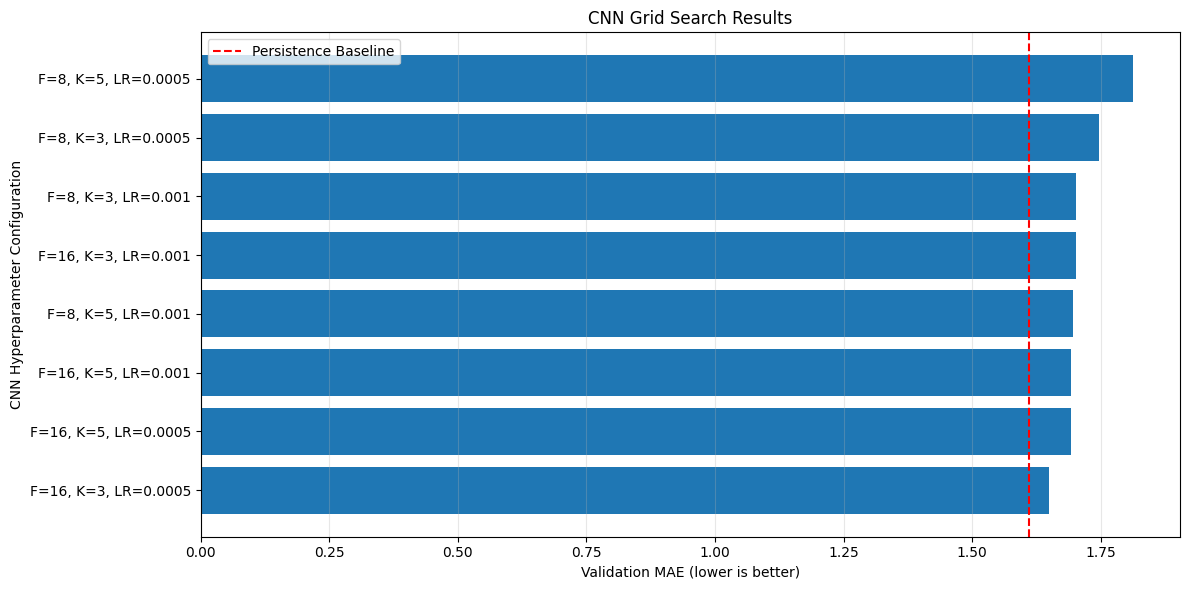

In [30]:
plt.style.use("default")

plot_df = grid_results_df.sort_values("Val MAE")

labels = [
    f"F={int(row['Filters'])}, "
    f"K={int(row['Kernel Size'])}, "
    f"LR={row['Learning Rate']}"
    for _, row in plot_df.iterrows()
]

plt.figure(figsize=(12, 6))

plt.barh(
    labels,
    plot_df["Val MAE"]
)

plt.axvline(
    naive_mae,
    color="red",
    linestyle="--",
    label="Persistence Baseline"
)

plt.xlabel("Validation MAE (lower is better)")
plt.ylabel("CNN Hyperparameter Configuration")
plt.title("CNN Grid Search Results")

plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Figure 7. CNN Grid Search Results**

No configuration beat the persistence MAE, and the best (16 filters, kernel size 3, learning rate 0.0005) was 0.038 above it.

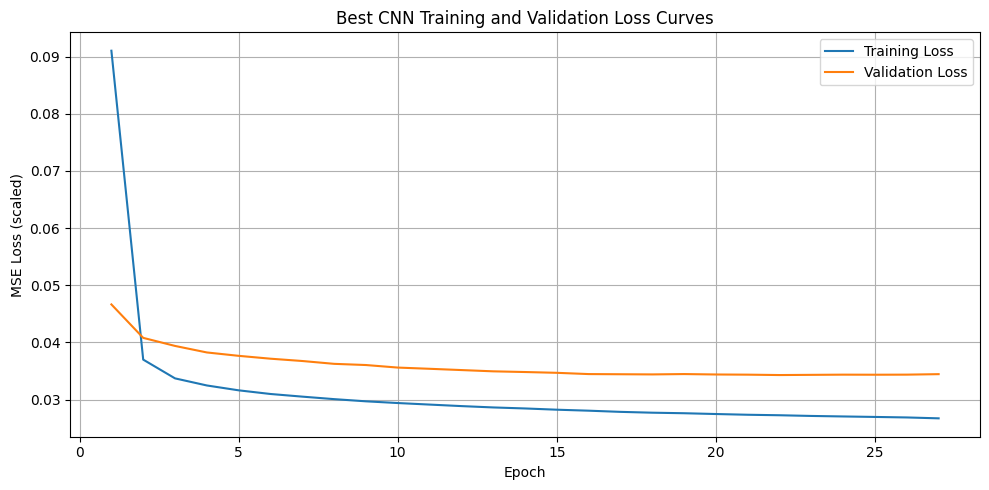

In [31]:
epochs_range = range(
    1, len(best_history["loss"]) + 1
)

plt.style.use("default")
plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    best_history["loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    best_history["val_loss"],
    label="Validation Loss"
)

plt.title("Best CNN Training and Validation Loss Curves")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss (scaled)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Figure 8. Best CNN Learning Curves**

Validation loss flattens after about epoch 15, and early stopping ended training at epoch 27 with the epoch 22 weights restored.

### Final Model Comparison

In [32]:
# Table 3: Final comparison including the tuned CNN

best_row = grid_results_sorted.iloc[0]

tuned_row = pd.DataFrame([{
    "Model": (
        f"CNN (tuned: F={int(best_row['Filters'])}, "
        f"K={int(best_row['Kernel Size'])}, "
        f"LR={best_row['Learning Rate']})"
    ),
    "Val MAE": best_row["Val MAE"],
    "Val RMSE": best_row["Val RMSE"],
    "Parameters": int(best_row["Parameters"]),
    "Training Time (s)": best_row["Training Time (s)"],
    "MAE Improvement (%)": improvement(best_row["Val MAE"]),
    "RMSE Improvement (%)": (
        (naive_rmse - best_row["Val RMSE"]) / naive_rmse * 100
    )
}])

final_comparison_df = pd.concat(
    [comparison_df, tuned_row],
    ignore_index=True
)

final_comparison_df.to_csv(
    LOG_DIR / "final_comparison.csv",
    index=False
)

display(final_comparison_df.round(4))

,Model,Val MAE,Val RMSE,Parameters,Training Time (s),MAE Improvement (%),RMSE Improvement (%)
0,Persistence,1.6107,3.6799,0,0.0000,0.0000,0.0000
1,MLP,2.0532,3.6332,1217,9.5993,-27.4665,1.2673
2,CNN,1.6962,3.4651,2385,25.0180,-5.3062,5.8373
3,"CNN (tuned: F=16, K=3, LR=0.0005)",1.6485,3.4295,4705,32.7884,-2.3473,6.8036


The tuned CNN reduced validation MAE from 1.6962 to 1.6485 and had the lowest RMSE of all models (3.4295, 6.80% below persistence), but its MAE is still 2.35% worse than persistence.

## 12. Conclusion and Unresolved Risk

### Concrete Conclusion

The CNN outperformed the MLP in predicting Plant 1 solar generation 10 minutes ahead, and grid search reduced the CNN's validation MAE from 1.6962 to 1.6485 (about 2.81%). However, the persistence baseline still achieved the lowest validation MAE (1.6107), which shows that the most recent observation is a very strong predictor at this horizon. On RMSE, every neural model beat persistence, and the tuned CNN was lowest at 3.4295 (6.80% lower), suggesting the networks reduce large errors at the cost of slightly larger typical errors.

### Unresolved Risk and Future Investigation

One unresolved risk is the model's ability to predict sudden fluctuations in solar generation. The persistence baseline assumes that generation remains unchanged over the next 10 minutes, while the MLP and CNN may also struggle to capture rapid changes.

In Stage 2, RNN, LSTM/GRU, and TCN models will be implemented and compared using the same forecasting protocol. Prediction errors during periods of rapid generation changes will be examined to determine whether sequence-based models can better capture short-term temporal dynamics.